In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error,r2_score

In [5]:
housing=fetch_california_housing()
data=pd.DataFrame(housing.data,columns=housing.feature_names)
data["Price"]=housing.target

In [6]:
X=data[['AveRooms']].values
y=data['Price'].values

In [13]:
X_train,X_test,y_train,y_test=train_test_split(
X,y,
test_size=0.2,
random_state=42
)

In [15]:
s=StandardScaler()
X_train_scaled=s.fit_transform(X_train)
X_test_scaled=s.transform(X_test)

In [29]:
w=0
b=0
cost_history=[]
lr=0.01
epochs=1000

n=len(X_train_scaled)
for i in range(epochs):
  y_pred=w*X_train_scaled.flatten()+b

  cost=(1/(2*n)) * np.sum((y_pred-y_train)**2)
  cost_history.append(cost)

  dw=(1/n)*np.sum((y_pred-y_train)*X_train_scaled.flatten())
  db=(1/n)*np.sum(y_pred-y_train)

  w=w-lr*dw
  b=b-lr*dw

  if i%100==0:
    print(f"Epoch{i},Cost={cost:.4f}")
y_pred_gd=w*X_test_scaled.flatten()+b


Epoch0,Cost=2.8149
Epoch100,Cost=2.5664
Epoch200,Cost=2.4822
Epoch300,Cost=2.4523
Epoch400,Cost=2.4414
Epoch500,Cost=2.4375
Epoch600,Cost=2.4360
Epoch700,Cost=2.4355
Epoch800,Cost=2.4353
Epoch900,Cost=2.4353


In [30]:
print("Gradient Descent")
print("-----------------")
print("Weight:",w)
print("Bias:",b)
print("MSE:", mean_squared_error(y_test,y_pred_gd))
print("R2:",r2_score(y_test,y_pred_gd))

Gradient Descent
-----------------
Weight: 0.18323090648660553
Bias: 0.18323090648660553
MSE: 4.8046131484493015
R2: -2.666498954318095


In [31]:
#Normal Equation
X_train_ne =np.c_[np.ones((len(X_train),1)),X_train]
X_test_ne=np.c_[np.ones((len(X_test),1)),X_test]
theta=np.linalg.inv(X_train_ne.T@X_train_ne)@X_train_ne.T@y_train
y_pred_ne=X_test_ne@theta

In [32]:
print("\nNormal Equation")
print("----------------")
print("Intercept:", theta[0])
print("Slope:", theta[1])
print("MSE:" ,mean_squared_error(y_test,y_pred_ne))
print("R2 Score:",r2_score(y_test,y_pred_ne))


Normal Equation
----------------
Intercept: 1.6547622685968384
Slope: 0.07675558963126795
MSE: 1.2923314440807303
R2 Score: 0.013795337532284568


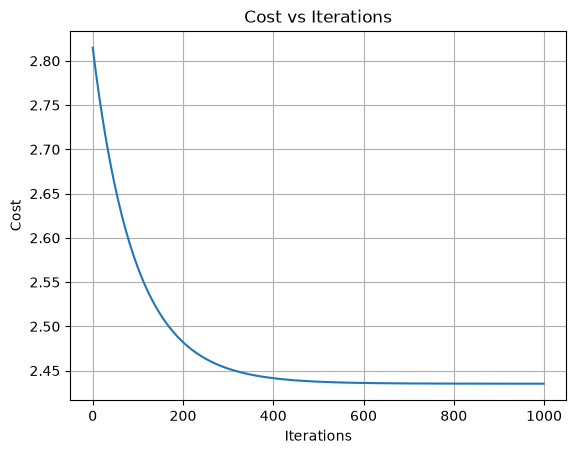

In [33]:
plt.plot(cost_history)
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.title('Cost vs Iterations')
plt.grid(True)
plt.show()

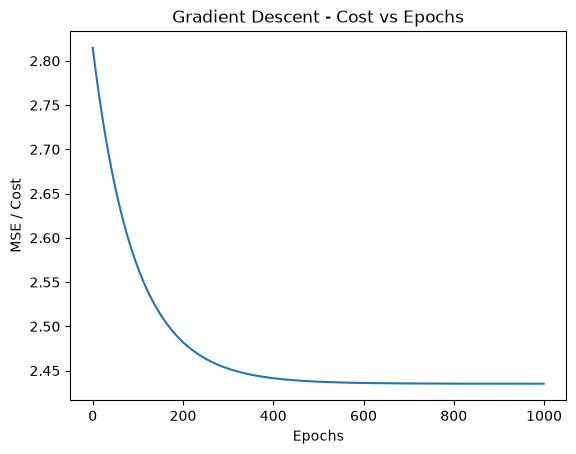

In [35]:
plt.plot(cost_history)
plt.xlabel("Epochs")
plt.ylabel("MSE / Cost")
plt.title("Gradient Descent - Cost vs Epochs")
plt.show()

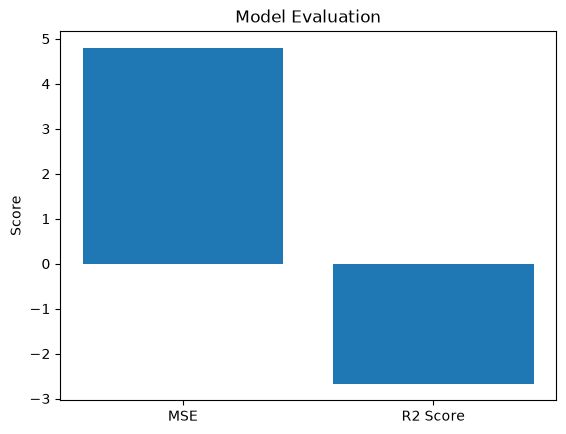

In [36]:
mse = mean_squared_error(y_test, y_pred_gd)
r2 = r2_score(y_test, y_pred_gd)

plt.bar(["MSE", "R2 Score"], [mse, r2])
plt.title("Model Evaluation")
plt.ylabel("Score")
plt.show()